# **MMME4125 2026/2027 Coursework**

**Student Name:** [Toh Chen Yee]

**Student ID:** [20494385]

# **Project Description**

In this coursework, you will analise historical data and build your own machine learning pipeline demonstrating your knowledge on data exploration, data preparation and machine learning model development to solve a prediction or classification task  of an engineering domain problem.

**Dataset:** You will select a data set from a range of data sets provided in this module's Moodle page.

**Overall task:** Utilising your selected data set, you will build at least two models of your choice either for regression or classification (depending on the data set you selected) from the ones covered during lectures (e.g. NN, Decision Trees, Randon Forest, CNN to name a few examples). Employ appropriate methods from the pandas, matplotlib, keras and sklearn libraries to analyse and process the dataset and for building predictive models.

**Note:** You must use only pandas, numpy, matplotlib, keras and sklearn or any other specific library that was covered during class for example for data augmentation. Do not use other libraries or external packages. Use of such packages may receive zero credit for the affected parts. 

**Format:** Use this Jupyter Notebook as a template to write your report/answers to questions in Markdown cells, supported by your source code in Code cells.

The project (and this notebook) are structured in three main tasks:

**(Task 1)** -  Data set selection & data exploration : Once you select the data set you will carry out an initial Exploratory Data Analysis (EDA). Some data sets might be too large, containing multiple features or measurements of multiple variables. As you explore your data, you will make a decision of which sub set of your data you will use for your prediction/classification task. **You will then discuss this decision with your lab tutor (you will book a slot for this during lab hours) and get feedback**. As it will be indicated later in this notebook, you will add as markdown your analysis of the EDA results, the feedback provided by the tutor and how this has been taken into account to move to the next task. 

**(Task 2)** - Data preparation : with your chosen dataset (or subset), you will carry out the data preparation. This will include data visualisation (e.g. patterns, class imbalance, outliers), dealing with any missing values, outlier handling, scaling/normalisation, feature extraction, data reduction/augmentation, creating of training,validaton and test sets). 

**(Task 3)** - Model Development & Metrics Analysis : once your data set is ready, select two ML approaches from the ones covered during the lectures and discuss your selection with your lab tutor (**you will need to book a second lab slot for this and get feedback**). You will add in a Markdown cell your rationale for chosing such models, providing details of the feedback provided by the lab tutor and how it was used to move forward. Additional rationale for the specific hyper-parameters should also be included. Implementation should be added in a Code cell with appropriate code comments. Appropriate metrics for the model used should be implemented and presented (e.g. RMSE, Precision, Recall, F-Score, confusion matrix). You may want to try multiple hyper parameters to understand how the model behaves and if further iprovement can be obtained. In a Markdown cell, please explain the results obtained on both models and present a discussion of results. This discussion should include your insights on how model design/hyper-parameters affected the quality of the results.


Ensure your code produces the corresponding plots or results addressing the questions. Rename this .ipynb file to 202627_MMME4125_cw_XXX.ipynb, where XXX is your username (e.g., psxyz), and submit it to Moodle by **DATE**

**Marks**: The coursework is worth a total of 100 marks (accounting for 70% of the module grade). Marks will be awarded based on your understanding of machine learning theories, the informativeness and presentation of your code, visualisations, results (e.g., code comments, necessary labels in plots) and analysis, evidence of feedback and how it was addressed, your self-learning ability in solving the specific problem, and how succinct and clear your report writing is.

In [1]:
# You can change the import statements as you wish, but you should not use any library beyond pandas, numpy, matplotlib, and sklearn.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

<div class="alert alert-success" style="text-align:left;">
<h2>Task 1. Dataset Selection & Exploratory Data Analysis<span style="float:right;">[25 marks]</span></h2></div>

### Task 1a. <span style="color:red">(10 marks)</span>

Start by introducing the engineering problem that you will be addressing, what the current industrial practice is to solve this problem and why ML is a good approach to solve it (3 marks). Explain the data set you have selected by providing details on what each variable represents, if you suspect there are any likely measurement problems, if there are any variables that could introduce leakage and if any mechanical principles may provide initial plausible relationships across these variables (5 marks).  Finally explain why this is a regression or a classification task (2 marks).



High-entropy alloys (HEA) have multiple phase classification that include, BCC_SS, FCC+BCC_SS, FCC_SS or Im (intermetallic, laves or martensitic)
and being able to predict then classify stated microstructural phases accurately [1].

Current industrial practice is predicting inorganic material relies on material knowledge on alloy behaviours, 
human intuition and experimentation [1].For example, the current industrial practice known for metallic glass alloy specifically, relies on empirical reasoning (concluding alloys with many element of varying sizes have a higher chance to form glasses.) and experimentation [1].

ML is appropriate since it is able to take a large alloy dataset to learn and build a model to make predictions[2]. For example, using a model
to predict properties of a material and approximate its chemical effects [3].

The dataset contains 1360 columns (excluding 1st column of sequential numbering) and 53 rows.
The variables are as follow:

Column 0: Alloy ID

Column 1: Alloy

Column 2 - 26: Composition (Al, Co, Cr, Fe, Ni, Cu, Mn, Ti, V, Nb, Mo, Zr, Hf, Ta, W, C, Mg, Zn, Si, Re, N, Sc, Li, Sn, Be)  

Column 27- 36: Design Parameters (Num_of_Elem, Density_calc,dHmix, dSmix, dGmix, Tm, n.Para, Atom.Size.Diff, Elect.Diff, VEC)

Column 37 - 44: Processing Parameters (Sythesis_Route, Hot-Cold_Working, Homogenization_Temp, Homogenization_Time, Annealing_Temp,
                Annealing_Time (min), Quenching, HPR)

Column 45 - 49: Microstructure and Phases (Microstructure_	Multiphase, IM_Structure, Microstructure, Phases)

Column 50: References

Column 51-52: Unnamed:51, Unnamed:52 (Possibly missing dataset) 


Some measurement problems include inconsistent variable type under "Annealing_Temp" where it is a string type.
All the "_Temp" variables are float 64 which only accept numbers. Number such as "600?" is under "Annealing_Temp" listed as uncertainty
which will affect calculations in model training.

Secondly, design parameters have a lot of missing data from column 37-44 under variables such as "Homogenization_Temp" or"Homogenization_Time"

Lastly, there are inconsistent labelling under "Microstructure_" such as "BCC?+?FCC" as uncertainties.

Some variables that might lead to data leakage are from column 45-49 where variables such as "Microstructures" and "Phases"
share similar information. For example, a number alloys Microstructure of "BCC+IM" results in Phases to be "IM". When predicting phases
and if Phases were to be included in training, the ML model might conclude based on labels instead of learning the alloy structure itself.
It will deduce any "+IM" microstructure is an "IM" phase.

This is  a classification task where the ML model will need to classify an alloy whether it is a:
FCC, BCC, FCC+BCC or IM microstructure. 

Source:
1-A general-purpose machine learning framework for predicting properties of inorganic materials
2 - Machine learning for molecular and materials science
3 -A general-purpose machine learning framework for predicting properties of inorganic materials


### Task 1b. <span style="color:red">(5 marks)</span>

Select a subset of the data to be visualised. Include a rationale for inspecting this particular subset of data (2 mark). Produce at least 3 plots (1 mark each) to visualise patterns, distribution, class imbalance, outliers and correlations. The types of plots you use will  be determined by the type of data you are handling. These plots should be informative of the next steps you will carry out during data preparation.

Rationale: 
According to the paper "Machine learning-based prediction of phases in high-entropy alloys: A data article", 
The parameters chosen to create a subset were:
- enthalpy of mixing for a multi-component alloy-system (dHmix),
- entropy of mixing of a multi-component alloy system (dSmix)
- melting temperature estimate (Tm)
- valence electron concentration (VEC)
Since these are parameters needed to predict accurately the phase of a HEA [1].

Additional parameters stated below were chosen due abundant of non-null and non-missing values.
- n.Para
- Atom size difference (Atom.Size.Diff)
- Elect.Diff 
- dGmix

The final variable "phases" was picked since it's the variable the ML would need to predict
- Phases

The element composition from columns 2-26 (Al,Co,Cr, etc) were not chosen due to sparse data (too many 0s its columns)
Likewise, processing parameters from column 37-44 contain almost no data (e.g Hold-Cold Working column only contains 444 rows of non-null data out of 1361 rows )


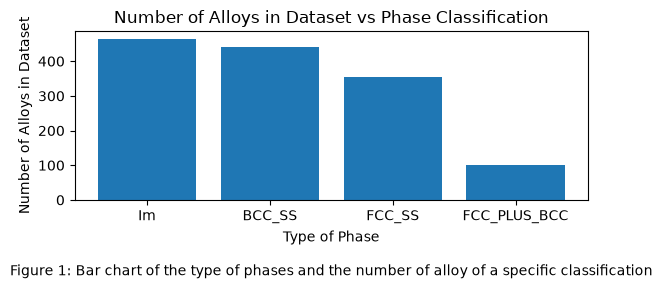

1355
1360
1360
1360
1359
1360
1360
1360


In [2]:
data = pd.read_csv("HEA Phase DataSet v1d.csv", encoding="latin-1") 


# Bar chart (Class Imbalance)
counts = data["Phases"].value_counts()  # Matplot lib bar char - 4

fig, axes = plt.subplots(figsize=(6, 3))
axes.bar(counts.index, counts.values)
axes.set(ylabel="Number of Alloys in Dataset", title="Number of Alloys in Dataset vs Phase Classification")
axes.set(xlabel="Type of Phase\n\nFigure 1: Bar chart of the type of phases and the number of alloy of a specific classification")
fig.tight_layout(); plt.show()


#Notes:
#Shows mild class imbalance with FCC+BCC - has more alloy data for IM, BCC_SS and  FCC_SS.
# FCC+BCC lacks sample alloy data compared to the 3 other phases -> might be problematic for ML where less data = less accurate prediction

#checking to see which column has least missing values - panda  notna.Sum() checks how many non-null rows  
### NOT RELATED DO NOT MARK
print(data["Density_calc"].notna().sum())  #1355 rows filled -
print(data["dHmix"].notna().sum())  #1360  
print(data["dSmix"].notna().sum())  # 1360
print(data["dGmix"].notna().sum()) #1360
print(data["n.Para"].notna().sum())   #1359
print(data["Atom.Size.Diff"].notna().sum()) #1360
print(data["Elect.Diff"].notna().sum()) #1360
print(data["VEC"].notna().sum()) #1360
### NOT RELATED DO NOT MARK
# !! DATASET HAS 1361 rows




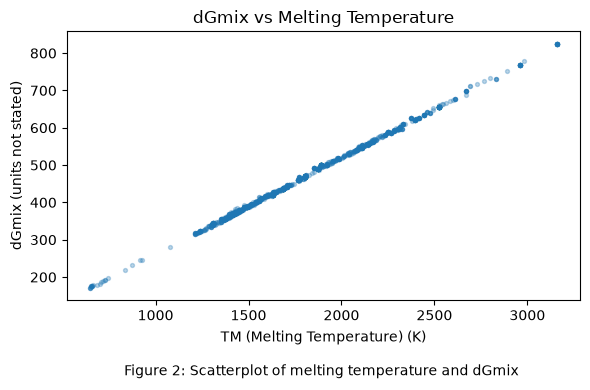

In [3]:
#correlation graph  

fig, axes = plt.subplots(figsize=(6, 4))
axes.scatter(data["Tm"], data["dGmix"], s=8, alpha=0.3)
axes.set(xlabel="TM (Melting Temperature) (K)\n\nFigure 2: Scatterplot of melting temperature and dGmix ",
          ylabel="dGmix (units not stated)",
       title="dGmix vs Melting Temperature")
fig.tight_layout(); plt.show()

#Notes:
#shows as melting temperature increases, dGmix increases proportionally 

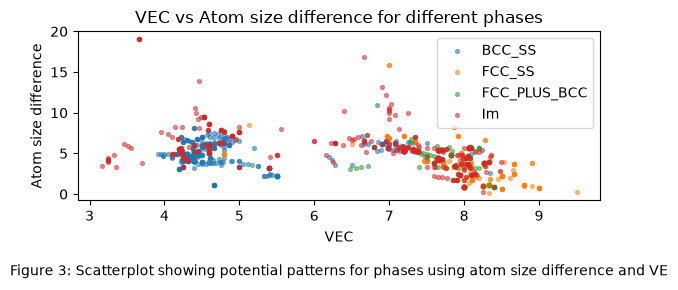

In [4]:
#Scatterplot of patterns in observing phases

fig, axes = plt.subplots(figsize=(6, 3))

Bcc  = data.loc[data["Phases"] == "BCC_SS"]   # from matplotlib to check each row //  == is to compare TRue or false bool if row phase is X & data.loc filters out False, keep only true
Fcc  = data.loc[data["Phases"] == "FCC_SS"]
Both = data.loc[data["Phases"] == "FCC_PLUS_BCC"]
Im   = data.loc[data["Phases"] == "Im"]


# plot only True values & it's respective Vec and atom size diff
axes.scatter(Bcc["VEC"],  Bcc["Atom.Size.Diff"],  s=8, alpha=0.5, label="BCC_SS")
axes.scatter(Fcc["VEC"],  Fcc["Atom.Size.Diff"],  s=8, alpha=0.5, label="FCC_SS")
axes.scatter(Both["VEC"], Both["Atom.Size.Diff"], s=8, alpha=0.5, label="FCC_PLUS_BCC")
axes.scatter(Im["VEC"],   Im["Atom.Size.Diff"],   s=8, alpha=0.5, label="Im")

axes.set(xlabel="VEC\n\nFigure 3: Scatterplot showing potential patterns for phases using atom size difference and VE", 
         ylabel="Atom size difference",
       title="VEC vs Atom size difference for different phases")

axes.legend()
fig.tight_layout(); plt.show()

#Notes:
#graph replicated from main paper fig 1b REFER TO MAIN PAPER
#Purpose is to predict phase classification through using inputs of VEC and  Atom size diff

#Able to observe e.g BCC_SS mainly has a low atom size diff and low VEC and some around High VEC

In [ ]:
#copied from  matplotlib - 6 box plot trying to identify outliers

states = ["BCC_SS", "FCC_SS", "FCC_PLUS_BCC", "Im"]
groups = [data.loc[data["Phases"] == s, "Atom.Size.Diff"] for s in states]
fig, axes = plt.subplots(figsize=(6, 3))
axes.boxplot(groups, whis=1.5, showfliers=True)
axes.set_xticks([1, 2, 3, 4], states) # label the three boxes
axes.set(ylabel="Atom Size Difference", title="Differences of atomic sizes by phases")
axes.set(xlabel="Figure 4: Box plot for atom size difference for each phases")
fig.tight_layout(); plt.show()



##Find & inspect potential outliers 
im = data.loc[data["Phases"]== "Im", "Atom.Size.Diff"]
q1,q3 = im.quantile([0.25,0.75])
iqr = q3-q1
flagged = im.loc[ (im< q1-1.5*iqr) | (im>q3+1.5*iqr)]

print(len(flagged), "potential outliers from Im rows")

#Notes
#Orange line = median(
# FCC_SS has a lower median atom size diff compared to others (maybe can be use as identifer?)
# Im has the most outliers 
# BCC_SS, FCC_PLUS_BCC and IM 

NameError: name 'df' is not defined

### Task 1c. <span style="color:red">(10 marks)</span>

-By using your plots from 1b, provide an analysis of the data (e.g. observed patterns, correlations, potential best predictors) and briefly explain how each code snippet supports your evaluation of potential issues with the data (5 marks).

-Once you have done your analysis/insights you should discuss this with your lab tutor (you need to book a slot in lab hours for this), capture that feedback, report it here as well as a reflection of how the feedback informs the next steps of data processing (5 marks).

*Task 1c. Write here your analysis/insights of the EDA, the feedback you received from your tutor and your reflection of how the feedback influences your next steps on the data processing.*

Based on figure 1, FCC_PLUS_BCC contains the least amount of alloy data which shows a class imbalance of data compared to other phases that exceeds 300+ alloy cases.
Fewer data for the model to learn, meaning less accuracy to identify an alloy to be a FCC_PLUS_BCC.

Based on figure 2,the relationship between melting temperature (TM) and dGmix shows a perfect positive correlation

Based on figure 3, BCC_SS exhibits properties of having mostly low VEC and low atomic size difference and some high VEC with low atomic size.
Likewise, FCC_SS alloy mostly results in a high VEC but low atomic size difference. 
A potential issue shows Im appears to overlap with the properties of BCC_SS and FCC_SS, which might cause the ML to mis-classify Im as either. 

Based on figure 4, the box plot shows that FCC_SS has a lower median value compared to the other phases, which can make as a potential identifying property.
However, Im has the most outliers which will need further investigation to see whether it needs to remain or remove.

<div class="alert alert-success" style="text-align:left;">
<h2>Task 2. Data Preparation<span style="float:right;">[40 marks]</span></h2></div>

### <span style="color:red">IMPORTANT NOTE: </span> 
This the beginning of your ML building pipeline. All transformations that happen to the data from here onwards may be stateless or stateful. Make a concious decision at which step of the entire process you need to split your data set into training, validation and test set. **Add an additional Code cell** for data splitting when you think it is reasonable to do so as well as **add a Markdown cell** to explain why the data set is splitted at this point of the ML pipeline and the impact data transformation operations might have on the validity of the model if the splitting is not carried out beforehand. You should also justify your train-validation-test splitting stategy.
### <span style="color:red">(8 marks) </span>

### Task 2a. Data Cleaning <span style="color:red">(7 marks)</span>
Using the libraries specificied at the top of the notebook or any other one covered in class, start cleaning your data by handling missing values, handling any duplicates and deal with outliers. Justify your methods.

*Task 2a. Add your justification here*

In [ ]:
# Task 2a. Add your code here

### Task 2b. Data Transformation <span style="color:red">(5 marks)</span>
Perform any necessary normalisation and encoding of categorical variables. Please explain why this step is necessary when building a predictive model and justify the method used.

In [ ]:
# Task 2b. Add your code here

*Task 2b. Add your explanation here*

### Task 2c. Data Reduction/Augmentation  <span style="color:red">(10 marks)</span>

Based on your data set implement either data reduction or data augmentation depending on the needs of the problem and data (5 marks). Explain why data reduction or data augmentation is necessary in the context of your engineering problem and the data set you selected as well as justify the methods used (5 marks). One thing to note is that depending on your data set, data reduction might have to be done after Task 2d Feature Engineering, so make sure you apply these two steps (Task 2c and Task 2d) in the correct order according to your data. 

**Note**: If you do have to do 2d before 2c, then just make sure your code is in the correct order in the code cells below.

In [ ]:
# Task 2c. Add your code here

*Task 2c. Add your explanation and justification here*

### Task 2d. Feature Engineering   <span style="color:red">(10 marks)</span>

An important aspect of machine learning is understanding the feature space and shaping it before training. That is, preprocessing or reshaping the data in a way that provides more relevant information and an easier job for the regressor or classifier.

Perform any feature engineering that you might think it is ideal for the type of task you are aiming (4 marks). This could include statistical features, rolling window statistics,  frequency analysis (FFT) or any others covered in lectures. 

If either you are going to work directly with the raw data, or you will be engineering features, justify why this is the case in the context of the engineering problem you are trying to solve, justifying any specific features used (3 marks). In the case of raw data, perform any additional transformation that would be needed to work with this raw data directly. 

Assess whether all data is ready for model building. If not, complete the preparation of a model-ready dataframe from your cleaned dataset. More specifically, make sure to assess whether all predictors in your prepared dataframe are directly suitable for the machine learning task, state why this is the case  and state what(if anything) still needs processing, and process / make the necessary adjustment in the data accordingly (3 marks).

In [ ]:
# Task 2c. Add your code here

Task 2c. Add your explanations/justifications here

<div class="alert alert-success" style="text-align:left;">
<h2>Task 3. ML Model Building<span style="float:right;">[35 marks]</span></h2></div>

### Task 3a. Building a base  model <span style="color:red">(10 marks)</span>

Now, after meeting your tutor for the second time to discuss your preliminary model selection and reasons for such method (you need to book again a slot during your lab for this) select and build a baseline model from scratch (e.g. define architecture in the case of NN) to predict or classify according to your problem using the preprocessed dataset. 

- Train the model and report **three different** evaluation metrics (3 marks).
- Reflecting from  your tutor feedback, explain how this feedback influenced the ML model selected, why is it appropriate for the task? why the hyper-parameters used? (4 marks)
- For each metric, explain (in a single short sentence) why it is relevant and whether the observed value suggests sensible predictions/classifications, i.e. what the values within the metric mean (3 marks). 

In [ ]:
#Add your code here

Add your justification for metrics here and what the results obtained mean.

### Task 3b. Hyper-parameter exploration <span style="color:red">(10 marks)</span>

You have now build a base model, with some initial results. It is now your task to experiment with hyper-parameters (5 marks) to see if you can improve the quality of your results. It is up to you how you approach this process, but you need to justify (5 marks ) the approach you are taking and discuss the results. What effect is having the changes you are doing to the approach?

In [ ]:
#perform your different hyper-parameter optimisation/changes here

Add here your justification for how you are approaching the hyper-parameter tuning  and discuss your results.

### Task 3c. Additional Models and Final Analysis <span style="color:red">(15 marks)</span>

Implement at least one more method of your choice.Report model quality with clear evidence (metrics). Compare with the baseline using supportive tables or visualisations (4 marks), and discuss the strengths and limitations of each (3 marks). Finally, provide a discussion (8 marks) on:

Why this type of model and would you deploy it in a real environment? why?

Under what operating conditions would you not trust it? how could you improve it?

What additional sensor would you collect and why?

Are the important features physically plausible?

In [ ]:
# your implementaiton of additional methods here together with metrics

Add here your discussion on strengths and limitations of each method

DELETE EVERYTHING UNDER ONLY NOTES


In [ ]:
import pandas as pd

ds = pd.read_csv("HEA Phase DataSet v1d.csv", encoding="latin-1")   #no 6 - panda guide // reads CSV file and store in python as table
#File has � for degree symbol hence cannot be read, need to use encoding (https://stackoverflow.com/questions/10611455/what-is-character-encoding-and-why-should-i-bother-with-it)




In [ ]:
ds.shape  # Return number of (rows, columns in dataset)
#1361 rows, 53 columns (52 excl first column that displays row no)

(1361, 53)

In [ ]:
ds.head(40) # no-3 panda guide // prints  first 15 rows of dataset   

# Repeating dataset? e.g 5-7, 12-14 -> create bias/ affect weight of model?

,Alloy ID,Alloy,Al,Co,Cr,Fe,Ni,Cu,Mn,Ti,...,Quenching,HPR,Microstructure_,Multiphase,IM_Structure,Microstructure,Phases,References,Unnamed: 51,Unnamed: 52
0,Alloy 0000,Al0.5NbTaTiV,0.111111,0.0,0.000000,0.0,0.0,0.0,0.0,0.222222,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.1016/j.proeng.2012.03.043,NaN,NaN
1,Alloy 0001,Al0.75MoNbTiV,0.157895,0.0,0.000000,0.0,0.0,0.0,0.0,0.210526,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.3390/e16020870,NaN,NaN
2,Alloy 0002,Al0.25MoNbTiV,0.058824,0.0,0.000000,0.0,0.0,0.0,0.0,0.235294,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.3390/e16020870,NaN,NaN
3,Alloy 0003,Al0.25NbTaTiV,0.058824,0.0,0.000000,0.0,0.0,0.0,0.0,0.235294,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.1016/j.proeng.2012.03.043,NaN,NaN
4,Alloy 0004,Al0.2MoTaTiV,0.047619,0.0,0.000000,0.0,0.0,0.0,0.0,0.238095,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.4028/www.scientific.net/MSF.898.638,NaN,NaN
5,Alloy 0005,Al0.3NbTa0.8Ti1.4V0.2Zr1.3,0.060000,0.0,0.000000,0.0,0.0,0.0,0.0,0.280000,...,10°C/min,NaN,BCC,S,NaN,BCC,BCC_SS,10.1007/s11837-014-1066-0,NaN,NaN
6,Alloy 0006,Al0.3NbTa0.8Ti1.4V0.2Zr1.3,0.060000,0.0,0.000000,0.0,0.0,0.0,0.0,0.280000,...,10°C/min,NaN,BCC,S,NaN,BCC,BCC_SS,10.1007/s11837-014-1066-0,NaN,NaN
7,Alloy 0007,Al0.3NbTa0.8Ti1.4V0.2Zr1.3,0.060000,0.0,0.000000,0.0,0.0,0.0,0.0,0.280000,...,10°C/min,NaN,BCC,S,NaN,BCC,BCC_SS,10.1007/s11837-014-1066-0,NaN,NaN
8,Alloy 0008,Al0.5CrNbTi2V0.5,0.100000,0.0,0.200000,0.0,0.0,0.0,0.0,0.400000,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.1016/j.matlet.2016.11.030,NaN,NaN
9,Alloy 0009,Al0.5MoNbTiV,0.111111,0.0,0.000000,0.0,0.0,0.0,0.0,0.222222,...,NaN,NaN,BCC,S,NaN,BCC,BCC_SS,10.3390/e16020870,NaN,NaN


In [ ]:
ds.info()   #no 5 - panda guide // prints summary of dataset

#Issues !!!
#Panda treat columns as numbers (floats) - strings (str) cannot be plotted
#Annealing Temp - Str ??
#Missing Column 51-52


<class 'pandas.DataFrame'>
RangeIndex: 1361 entries, 0 to 1360
Data columns (total 53 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alloy ID              1360 non-null   str    
 1   Alloy                 1360 non-null   str    
 2   Al                    1360 non-null   float64
 3   Co                    1360 non-null   float64
 4   Cr                    1360 non-null   float64
 5   Fe                    1360 non-null   float64
 6   Ni                    1360 non-null   float64
 7   Cu                    1360 non-null   float64
 8   Mn                    1360 non-null   float64
 9   Ti                    1360 non-null   float64
 10  V                     1360 non-null   float64
 11  Nb                    1360 non-null   float64
 12  Mo                    1360 non-null   float64
 13  Zr                    1360 non-null   float64
 14  Hf                    1360 non-null   float64
 15  Ta                    1360 non-n

In [ ]:
ds.iloc[:5, 7:11]   # no 2 - panda guide // display up to 5 rows of data , display column titles x:y range (y is excluded & not shown) - 6:7 -> only column 6 is shown

#Trial & error for x:y
#0:2 -> alloy id, alloy type
#2:27 -> 25 element types
#28:37 -> numerical properties
#38-43 -> Processing parameters
# 44-50 -> Structure description & reference


### ISSUE!!!
#  51-52 column Unknown & Data missing (NaN)   
# Noticed from raw data file why some numbers contain "?" - e.g 600? 900? -> hence displays NaN
#


,Cu,Mn,Ti,V
0,0.0,0.0,0.222222,0.222222
1,0.0,0.0,0.210526,0.210526
2,0.0,0.0,0.235294,0.235294
3,0.0,0.0,0.235294,0.235294
4,0.0,0.0,0.238095,0.238095
